# Simulation

Run the current vehicle from launch through ascent, coast, restart, and departure.
The model uses rigid-body **6DOF dynamics and RK45**. Each run saves its settings,
plots, tables, and findings in [outputs/current](outputs/current/).

**Workflow:** edit the inputs below → review choices → Run All → read the results.
Start here; the [engineering checks](02_Engineering_Checks.ipynb) and
[verification register](03_Verification.ipynb) reuse the same flight.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from model.inputs import load_config, load_checks, load_study, input_tables, choices_table
from model.notebook import show_input_tables, show_table
from model.workspace import current_flight
from model.mission import integrated_tmi
from model.flight_evidence import flight_summary
from model.plotting import plot_results
from model.outputs import input_identity, save_flight
from model.trajectory import MU

%matplotlib inline

## 1. Inputs

Edit [vehicle.toml](inputs/vehicle.toml) for dimensions, masses, engines, and tank
geometry; [flight.toml](inputs/flight.toml) for wind, guidance, staging, control,
solver settings, and departure assumptions; [checks.toml](inputs/checks.toml) for
review limits and optional studies. The aerodynamic lookup is [aerodynamics.csv](inputs/aerodynamics.csv).

These tables read the saved files. Changing a table's display does not change the
simulation. `RECOMPUTE` only controls reuse of an identical saved run.

In [2]:
RECOMPUTE = False
run_inputs = input_identity()
config = load_config()
checks = load_checks()
departure_inputs = checks["integrated_tmi"]["inputs"]
review = load_study("flight_review")
refinement_settings = load_study("solver_refinement")
departure_targets = load_study("departure_targets")

main_inputs = [
    ("Payload", config["vehicle"]["payload_kg"], "kg"),
    ("Diameter", config["vehicle"]["diameter_m"], "m"),
    ("Length", sum(stage["length_m"] for stage in config["vehicle"]["stages"]), "m"),
    ("Selected fairing length", config["vehicle"]["fairing_length_m"], "m"),
    ("Wind at reference height", config["atmosphere"]["wind_reference_m_s"], "m/s"),
    ("Target parking altitude", config["guidance"]["target_altitude_m"] / 1000, "km"),
    ("Axial acceleration limit", config["limits"]["axial_g"], "g"),
    ("Lateral acceleration limit", config["limits"]["lateral_g"], "g"),
    ("AoA goal at maximum Qα", review["max_qalpha_aoa_deg"], "deg"),
    ("Required control / aero moment", config["limits"]["control_ratio"], "ratio"),
    ("Coast before restart", departure_inputs["coast_duration_s"], "s"),
    ("Restart propellant", departure_inputs["restart_propellant_kg"], "kg"),
    ("Departure C3 target", departure_inputs["target_c3_km2_s2"], "km²/s²"),
]
show_table(pd.DataFrame(main_inputs, columns=["Input", "Value", "Units"]).round(4))

stage_columns = {
    "name": "Stage", "dry_mass_kg": "Dry mass (kg)",
    "propellant_kg": "Loaded propellant (kg)", "thrust_N": "Thrust (N)",
    "isp_s": "Isp (s)", "gimbal_limit_deg": "Gimbal travel (deg)",
    "gimbal_rate_deg_s": "Gimbal rate (deg/s)",
}
show_table(pd.DataFrame(config["vehicle"]["stages"])[list(stage_columns)]
           .rename(columns=stage_columns).round(3))
show_input_tables(input_tables())

Input,Value,Units
Payload,4313.0000,kg
Diameter,5.4000,m
Length,58.7630,m
Selected fairing length,11.5000,m
Wind at reference height,7.6200,m/s
Target parking altitude,200.0000,km
Axial acceleration limit,6.0000,g
Lateral acceleration limit,2.0000,g
AoA goal at maximum Qα,4.0000,deg
Required control / aero moment,2.0000,ratio


Stage,Dry mass (kg),Loaded propellant (kg),Thrust (N),Isp (s),Gimbal travel (deg),Gimbal rate (deg/s)
Stage 1,28518.455,422704.567,6765000,350,5.0,5.0
Stage 2,7898.353,66123.849,890000,451,5.0,5.0


Input,Value,Units,Source
vehicle.diameter_m,5.4,m,inputs/vehicle.toml → vehicle.diameter_m
vehicle.payload_kg,4313,kg,inputs/vehicle.toml → vehicle.payload_kg
vehicle.fairing_kg,2155.27825,kg,inputs/vehicle.toml → vehicle.fairing_kg
vehicle.fairing_length_m,11.5,m,inputs/vehicle.toml → vehicle.fairing_length_m
vehicle.payload_cg_above_fairing_base_m,4.5,m,inputs/vehicle.toml → vehicle.payload_cg_above_fairing_base_m
vehicle.payload_length_m,6.0,m,inputs/vehicle.toml → vehicle.payload_length_m
vehicle.payload_radius_m,1.5,m,inputs/vehicle.toml → vehicle.payload_radius_m
vehicle.fairing_cg_above_base_m,6.5,m,inputs/vehicle.toml → vehicle.fairing_cg_above_base_m
vehicle.payload_station_m,51.763013,m,inputs/vehicle.toml → vehicle.payload_station_m
vehicle.stages.0.name,Stage 1,—,inputs/vehicle.toml → vehicle.stages.0.name


Input,Value,Units,Source
aero.file,inputs/aerodynamics.csv,—,inputs/vehicle.toml → aero.file
aero.reference_area_m2,22.90221,m²,inputs/vehicle.toml → aero.reference_area_m2
aero.cp_station_offset_m,0.0,m,inputs/vehicle.toml → aero.cp_station_offset_m
aero.cp_units,inches converted to m,—,inputs/vehicle.toml → aero.cp_units
aero.cp_datum,nose; RASAero-format inference,—,inputs/vehicle.toml → aero.cp_datum
aero.outside_domain_policy,endpoint hold AND flag every sample,—,inputs/vehicle.toml → aero.outside_domain_policy
aero.post_separation_policy,reuse full vehicle coefficients; unvalidated proxy,—,inputs/vehicle.toml → aero.post_separation_policy


Input,Value,Units,Source
description,Hyperion 28 Oct 2026 synced sizing geometry; selected low-AoA 6DOF RK45 guidance.,—,inputs/flight.toml → description


...

Input,Value,Units,Source
departure.coast_duration_s,600.000000,s,inputs/flight.toml → departure.coast_duration_s
departure.restart_propellant_kg,301.843504,kg,inputs/flight.toml → departure.restart_propellant_kg (uses vehicle.stages.1.startup_propellant_kg)
departure.target_c3_km2_s2,9.800000,km²/s²,inputs/flight.toml → departure.target_c3_km2_s2
departure.max_burn_duration_s,900.000000,s,inputs/flight.toml → departure.max_burn_duration_s
departure.output_step_s,2.000000,s,inputs/flight.toml → departure.output_step_s


Input,Value,Units,Source
shared.minimum_liftoff_thrust_to_weight,1.2,—,inputs/checks.toml → shared.minimum_liftoff_thrust_to_weight


Input,Value,Units,Source
calculations.flight_summary.basis,Current integrated 6DOF ascent; provisional aero/actuator/geometry inputs. No qualification claim.,—,inputs/checks.toml → calculations.flight_summary.basis
calculations.lambert_window.basis,Three source Horizons samples; no daily launch-window optimization or site-access proof.,—,inputs/checks.toml → calculations.lambert_window.basis
calculations.lambert_window.inputs.cases.0.departure_label,2033-04-27 00:00 TDB,—,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_label,2034-01-26 00:00 TDB,—,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.time_of_flight_s,23673600.0,s,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.departure_position_m,-120881146339.1056; -82360653324.81117; -35699389120.235855,m,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_position_m,151893899759.2209; 144802306802.2028; 62324284364.44935,m,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.departure_planet_velocity_m_s,17276.96831291071; -22058.20300105831; -9560.256841566952,m/s,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_planet_velocity_m_s,-16526.05562522464; 17003.911452690558; 8244.829125552214,m/s,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.long_way,Yes,—,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)


Input,Value,Units,Source
activities.PERF.2.05.A01.basis,Requirement numeric screen only; model-validation and open source conflicts remain.,—,inputs/checks.toml → activities.PERF.2.05.A01.basis
activities.PERF.2.05.A01.acceptance.0.metric,liftoff_thrust_to_weight,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.metric
activities.PERF.2.05.A01.acceptance.0.operator,>=,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.operator
activities.PERF.2.05.A01.acceptance.0.limit,1.2,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.limit (uses checks.shared.minimum_liftoff_thrust_to_weight)
activities.PERF.2.05.A01.acceptance.0.units,1,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.units
activities.PERF.2.05.A01.acceptance.0.source,PERF.2.05,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.source
activities.PERF.2.06.A01.basis,Requirement numeric screen only; model-validation and open source conflicts remain.,—,inputs/checks.toml → activities.PERF.2.06.A01.basis
activities.PERF.2.06.A01.acceptance.0.metric,max_axial_g,—,inputs/checks.toml → activities.PERF.2.06.A01.acceptance.0.metric
activities.PERF.2.06.A01.acceptance.0.operator,<=,—,inputs/checks.toml → activities.PERF.2.06.A01.acceptance.0.operator
activities.PERF.2.06.A01.acceptance.0.limit,6.0,—,inputs/checks.toml → activities.PERF.2.06.A01.acceptance.0.limit (uses limits.axial_g)


Input,Value,Units,Source
studies.tank_thickness.basis,"Pressure-only trade from Structures Sizing.xlsx, Tank Sizing!B3:D8 and Material Properties!B3:H3 (Al2219). The yield factor comes from STR.3.SYS.03; its separate ultimate factor is not evaluated here. Radius follows the selected vehicle. Material applicability, temperature, joints and combined flight loads still need review; this trade alone closes no activity.",—,inputs/checks.toml → studies.tank_thickness.basis
studies.tank_thickness.thicknesses_mm,1; 2; 3; 4; 5; 6,mm,inputs/checks.toml → studies.tank_thickness.thicknesses_mm
studies.tank_thickness.inputs.radius_m,2.7,m,inputs/checks.toml → studies.tank_thickness.inputs.radius_m (uses vehicle.diameter_m × 0.5)
studies.tank_thickness.inputs.pressure_pa,599999.764445,Pa,inputs/checks.toml → studies.tank_thickness.inputs.pressure_pa
studies.tank_thickness.inputs.axial_force_n,0,N,inputs/checks.toml → studies.tank_thickness.inputs.axial_force_n
studies.tank_thickness.inputs.bending_moment_nm,0,N m,inputs/checks.toml → studies.tank_thickness.inputs.bending_moment_nm
studies.tank_thickness.inputs.torque_nm,0,N m,inputs/checks.toml → studies.tank_thickness.inputs.torque_nm
studies.tank_thickness.inputs.yield_allowable_pa,296474563.606224,Pa,inputs/checks.toml → studies.tank_thickness.inputs.yield_allowable_pa
studies.tank_thickness.inputs.joint_efficiency,1,—,inputs/checks.toml → studies.tank_thickness.inputs.joint_efficiency
studies.tank_thickness.inputs.load_factor,1.25,—,inputs/checks.toml → studies.tank_thickness.inputs.load_factor


## 2. Choices and assumptions

The selected settings and their basis appear below. In particular, resolve the
fairing-length conflict, CP datum, aerodynamic reference geometry, and actuator
capability before treating the flight as validated evidence.

In [3]:
show_table(choices_table())
print("Departure basis:", checks["integrated_tmi"]["basis"])
print("Solver sensitivity enabled:", refinement_settings["enabled"])

Choice,Selection,Basis
Vehicle geometry,fairing_length_m: 11.5 m; diameter_m: 5.4 m,Selected sizing geometry. The master Payload sheet still gives a 14 m fairing; reconcile with CAD and the aero export.
CP interpretation,cp_units: inches converted to m; cp_datum: nose; RASAero-format inference,Inches are tentative user confirmation; datum is inferred and remains unverified.
Aerodynamic reference,reference_area_m2: 22.902210444669596 m²; outside_domain_policy: endpoint hold AND flag every sample; post_separation_policy: reuse full vehicle coefficients; unvalidated proxy,Source export geometry is unverified. Flag out-of-domain and separated-vehicle proxy samples.
Stage 1 control capability,gimbal_limit_deg: 5.0 deg; gimbal_rate_deg_s: 5.0 deg/s,"Assumed actuator capability, not approved hardware performance."
Stage 2 control capability,gimbal_limit_deg: 5.0 deg; gimbal_rate_deg_s: 5.0 deg/s,"Assumed actuator capability, not approved hardware performance."
Departure baseline,coast_duration_s: 600 s; restart_propellant_kg: 301.843504114127 kg; target_c3_km2_s2: 9.8 km²/s²,The verification target is provisional. The master target is retained as a separate comparison case; neither is a solved encounter.
Integrator,method: RK45; rtol: 2e-07; max_step_s: 0.4 s,Quaternion rigid-body 6DOF with discrete stage and fairing events; no flexible dynamics.
Atmosphere and wind,wind_reference_m_s: 7.62 m/s; wind_toward_deg_east_of_north: 90.0; temperature_offset_K: 0.0 K; density_scale: 1.0,Layered standard atmosphere and a deterministic wind profile; no measured launch sounding.
Coast and roll control,rcs_moment_Nm: 0.0 N m; roll_rcs_moment_Nm: 0.0 N m; control_ratio: 2.0,Evaluate all phases. No central-axis TVC roll authority is available.
Actuator response,actuator_time_constant_s: 0.15 s,Assumed first-order response; requires hardware confirmation.


Departure basis: The saved coast and restart debit are screening assumptions. Shared 6DOF prograde TMI; no Mars encounter targeting.
Solver sensitivity enabled: False


## 3. Run

The ascent result is reused only when its inputs, model, and saved results match.
Departure starts from the actual upper-stage cutoff state and uses the same
6DOF equations. Its prograde burn tests energy capability; it does not solve a
Mars encounter. C3 below zero means the vehicle remains Earth-bound.

In [4]:
context = current_flight(recompute=RECOMPUTE)
flight, summary, simulation = context
metrics = flight_summary(context)
reached_cutoff = any(event["event"] == "orbital_speed_cutoff" for event in summary["events"])
departure = None
if reached_cutoff:
    departure = integrated_tmi(context=context, **departure_inputs)
    departure_history = pd.DataFrame(departure["history"])
    departure_control_margin = departure_history.ratio2_margin_Nm.min()
    print("Departure ended because:", departure["status"].replace("_", " "))
else:
    print("Departure unavailable: the ascent did not reach orbital cutoff. Ascent results are retained.")

Departure ended because: residual propellant limit


## 4. Outputs

**Q** is dynamic pressure. **Qα** is Q multiplied by angle of attack. A negative
control margin means available control moment is below the configured multiple
of aerodynamic moment. Powered and engine-off results are reported separately.

In [5]:
rows = [
    ("Maximum Q", metrics["max_q_Pa"] / 1000, "kPa"),
    ("Maximum Qα", metrics["max_qalpha_Pa_deg"] / 1000, "kPa·deg"),
    ("AoA at maximum Qα", metrics["alpha_at_max_qalpha_deg"], "deg"),
    ("Peak axial acceleration", metrics["max_axial_g"], "g"),
    ("Peak lateral acceleration", metrics["max_lateral_g"], "g"),
    ("Liftoff thrust / weight", metrics["liftoff_thrust_to_weight"], "ratio"),
    ("Smallest powered control margin", metrics["minimum_powered_control_ratio_margin_Nm"] / 1000, "kN·m"),
    ("Smallest ascent margin including staging coast", metrics["minimum_control_ratio_margin_Nm"] / 1000, "kN·m"),
    ("Steering loss", metrics["steering_loss_m_s"], "m/s"),
    ("Drag loss", metrics["drag_loss_m_s"], "m/s"),
    ("Gravity loss", metrics["gravity_loss_m_s"], "m/s"),
]
if departure is not None:
    rows += [
        ("Target departure C3", departure["target_C3_km2_s2"], "km²/s²"),
        ("Achieved departure C3", departure["achieved_C3_km2_s2"], "km²/s²"),
        ("Departure C3 margin", departure["C3_margin_km2_s2"], "km²/s²"),
        ("Peak departure axial acceleration", departure["maximum_axial_g"], "g"),
        ("Peak departure lateral acceleration", departure["maximum_lateral_g"], "g"),
        ("Smallest departure control margin including coast", departure_control_margin / 1000, "kN·m"),
        ("Propellant after departure", departure["remaining_propellant_kg"], "kg"),
    ]
key_results = pd.DataFrame(rows, columns=["Result", "Value", "Units"])
show_table(key_results.round(4))

review_rows = [
    ("AoA at maximum Qα", metrics["alpha_at_max_qalpha_deg"] < review["max_qalpha_aoa_deg"]),
    ("Axial acceleration", metrics["max_axial_g"] <= config["limits"]["axial_g"]),
    ("Lateral acceleration", metrics["max_lateral_g"] <= config["limits"]["lateral_g"]),
    ("Powered control margin", metrics["minimum_powered_control_ratio_margin_Nm"] >= 0),
    ("Ascent control margin in every phase", metrics["minimum_control_ratio_margin_Nm"] >= 0),
]
if departure is not None:
    review_rows += [
        ("Departure target", departure["target_C3_reached"]),
        ("Departure axial acceleration", departure["axial_acceleration_screen_pass"]),
        ("Departure lateral acceleration", departure["lateral_acceleration_screen_pass"]),
        ("Departure control margin including coast", departure_control_margin >= 0),
    ]
review_results = pd.DataFrame(
    [(name, "Meets selected limit" if passed else "Needs attention") for name, passed in review_rows],
    columns=["Review", "Result"],
)
show_table(review_results)

Result,Value,Units
Maximum Q,17.8864,kPa
Maximum Qα,31.7243,kPa·deg
AoA at maximum Qα,2.1770,deg
Peak axial acceleration,5.6884,g
Peak lateral acceleration,0.0179,g
Liftoff thrust / weight,1.3046,ratio
Smallest powered control margin,253.7605,kN·m
Smallest ascent margin including staging coast,-12.7660,kN·m
Steering loss,1410.8195,m/s
Drag loss,19.7315,m/s


Review,Result
AoA at maximum Qα,Meets selected limit
Axial acceleration,Meets selected limit
Lateral acceleration,Meets selected limit
Powered control margin,Meets selected limit
Ascent control margin in every phase,Needs attention
Departure target,Needs attention
Departure axial acceleration,Meets selected limit
Departure lateral acceleration,Meets selected limit
Departure control margin including coast,Needs attention


### Flight plots

The five plot sheets retain position, orientation, flight-path angle, AoA,
thrust command, gimbal angle, speed/Mach, atmosphere, mass, inertia, and losses.
Markers identify maximum Q, maximum Qα, and peak acceleration loads. The gimbal
loss curve is a diagnostic already included in steering loss; do not add it again.

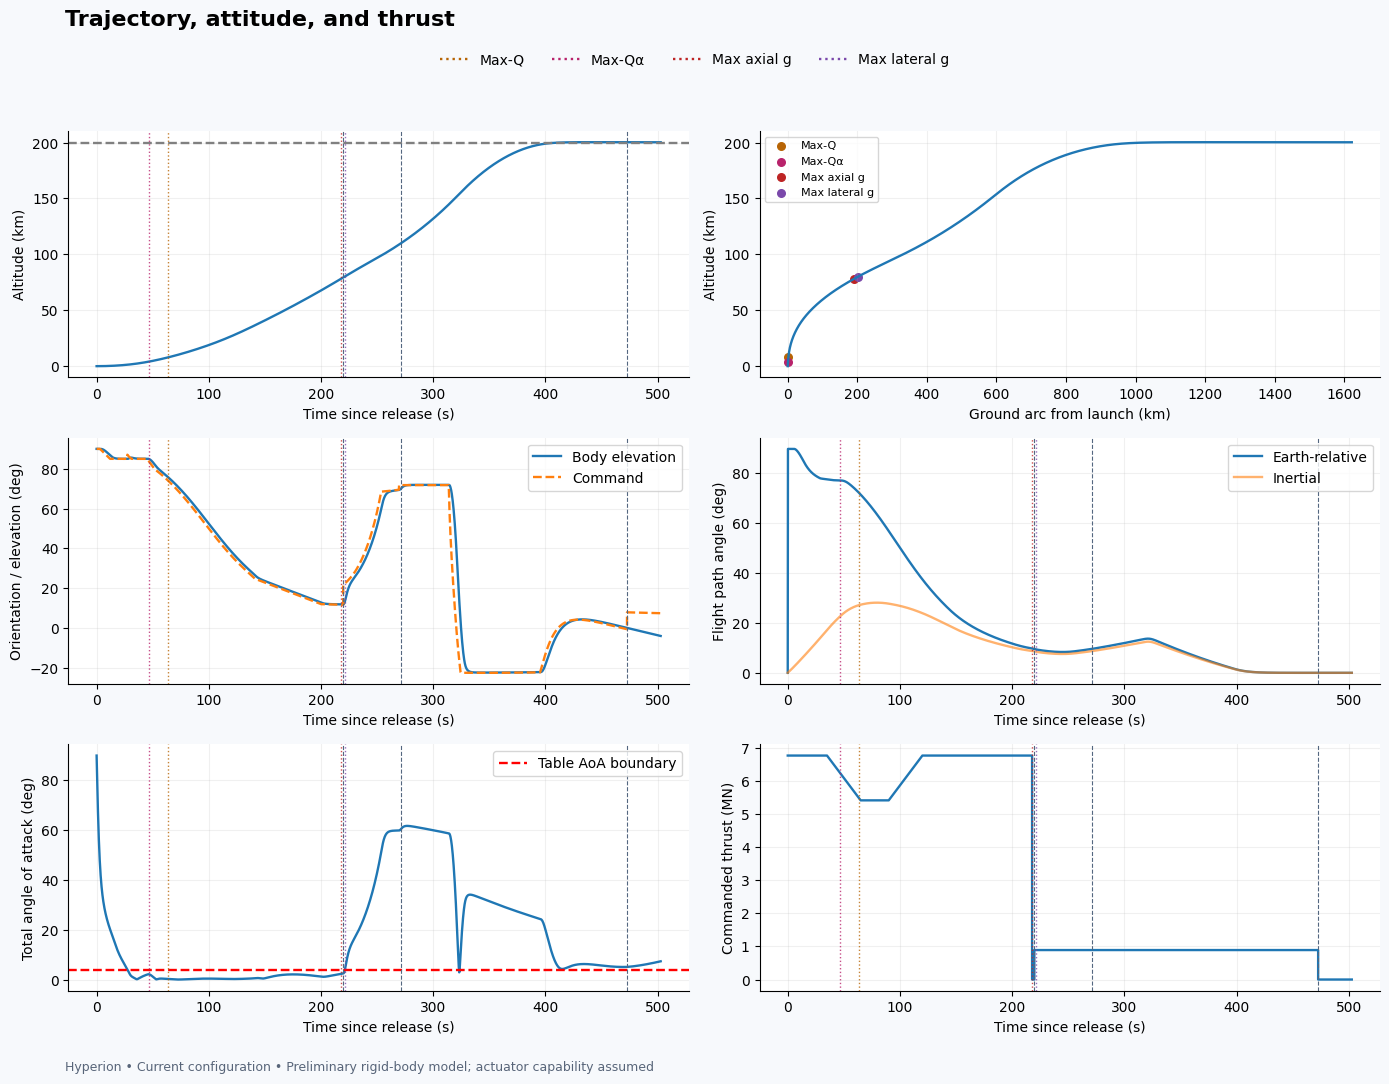

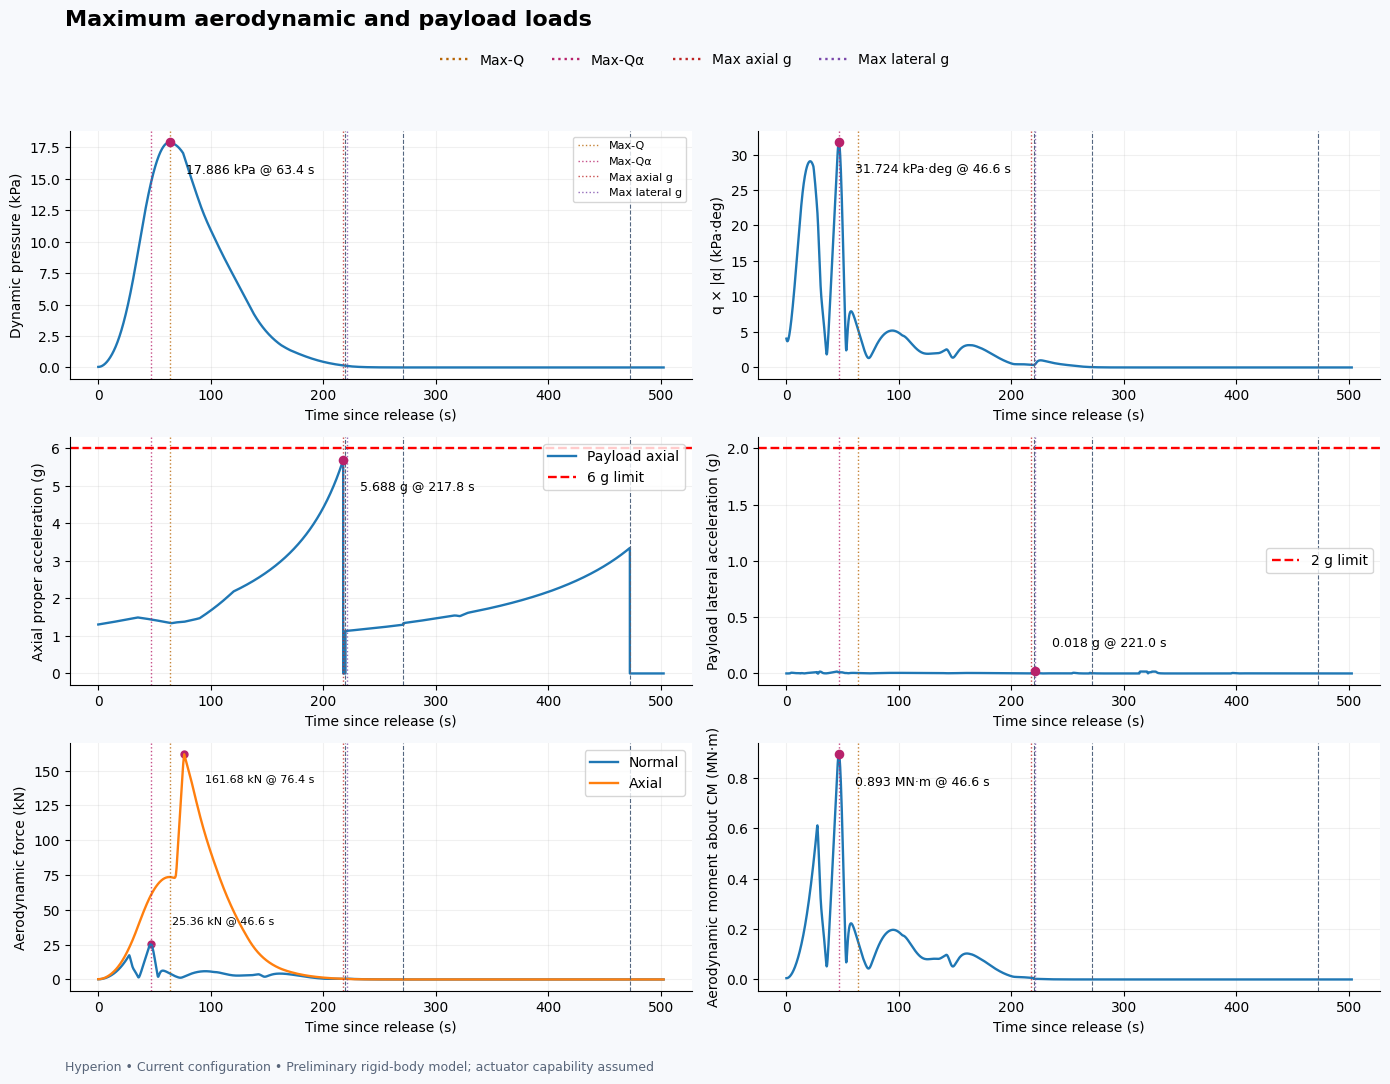

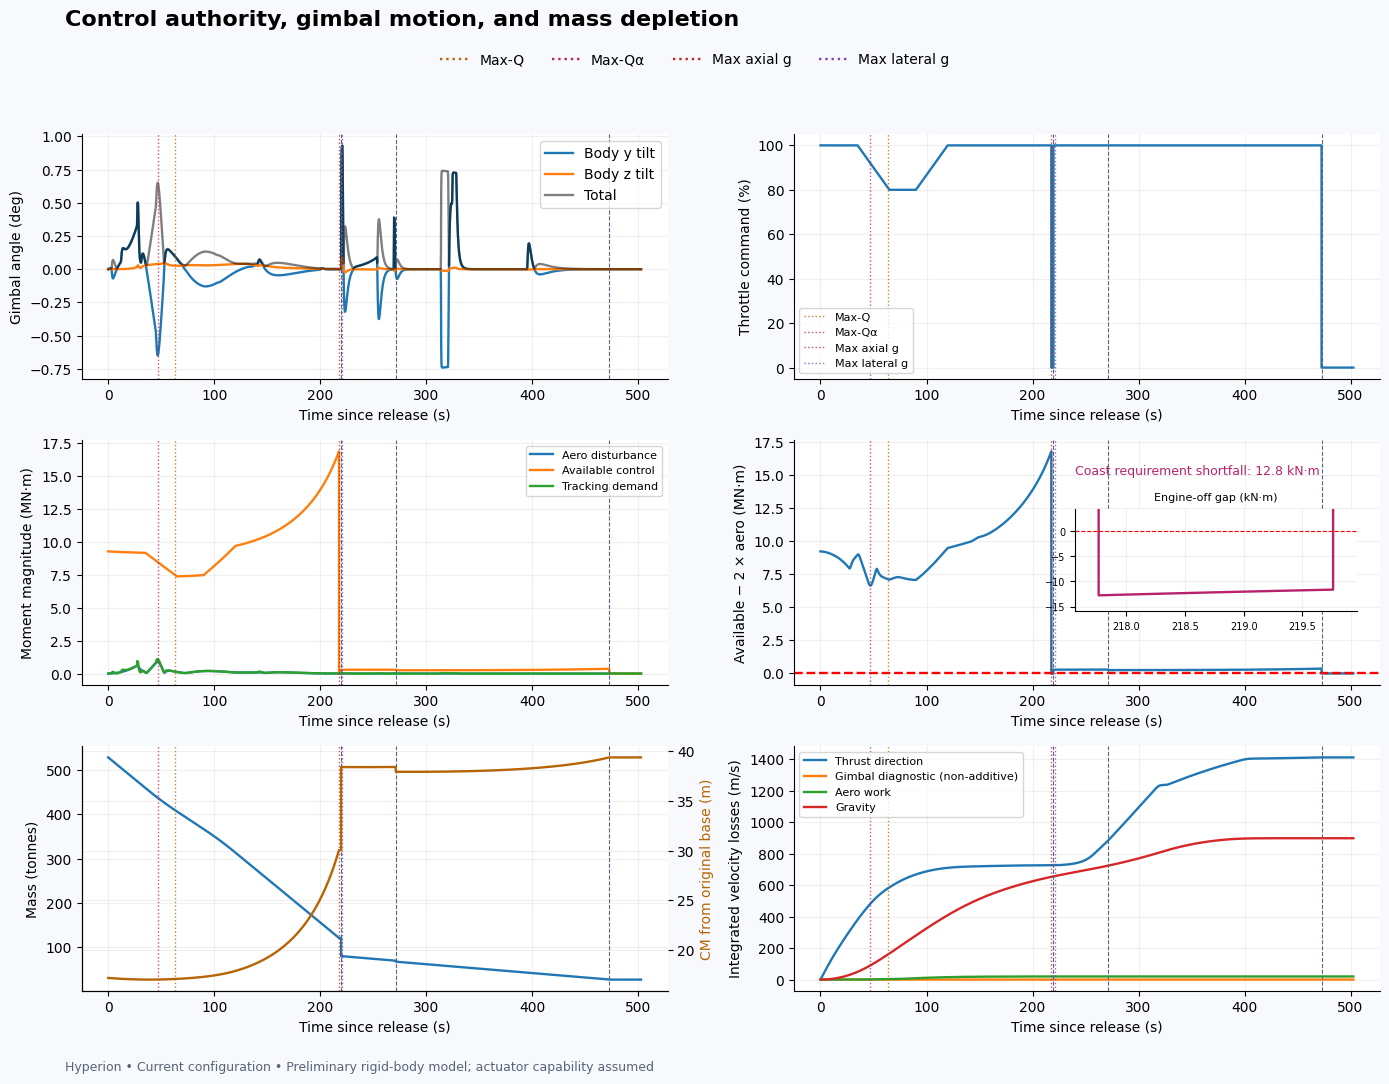

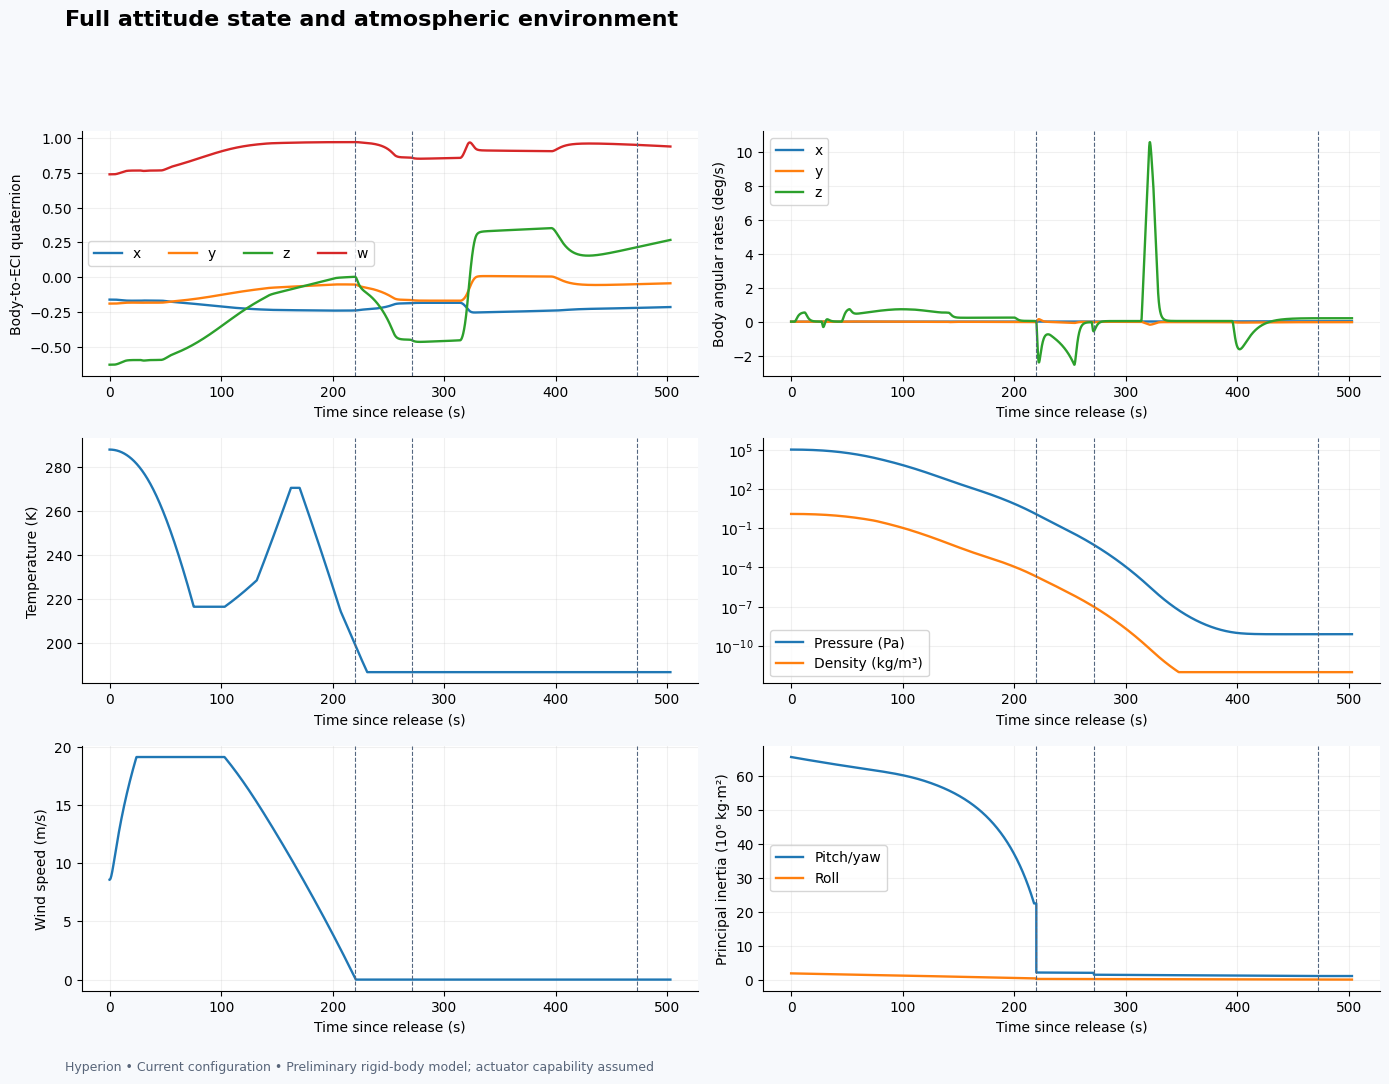

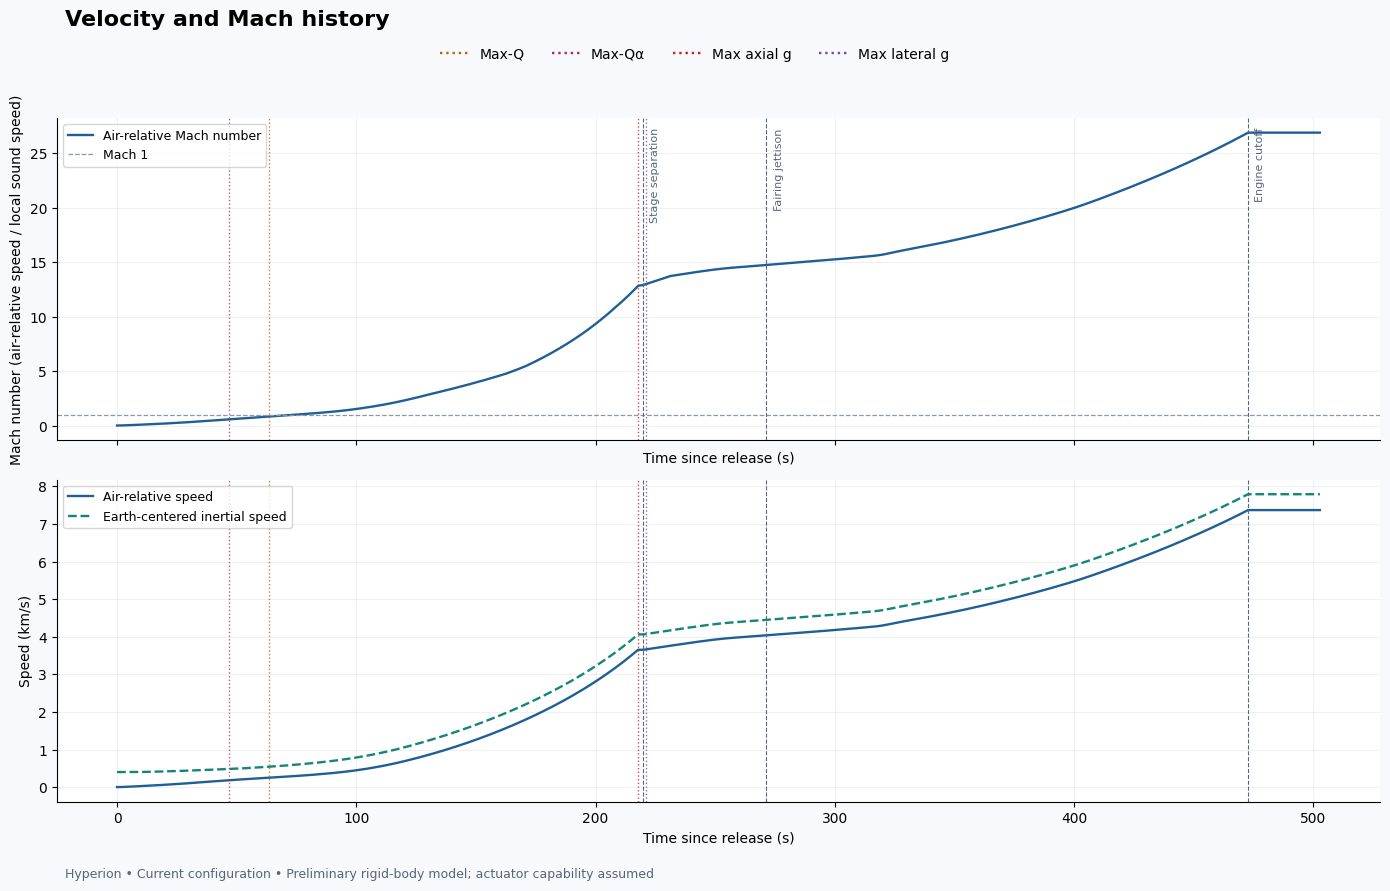

In [6]:
plot_names = ["trajectory", "loads", "control_and_mass", "attitude_and_atmosphere", "velocity_and_mach"]
figures = dict(zip(plot_names, plot_results(flight, summary, simulation.c)))
for figure in figures.values():
    display(figure)
    plt.close(figure)

### Coast, restart, and departure

Reference target lines come from the saved departure study. Remaining propellant
includes the required residual reserve; it is not all available for another burn.

The control plots include the entire departure coast and burn. A powered-only
capacity check cannot establish control authority while the engine is off.

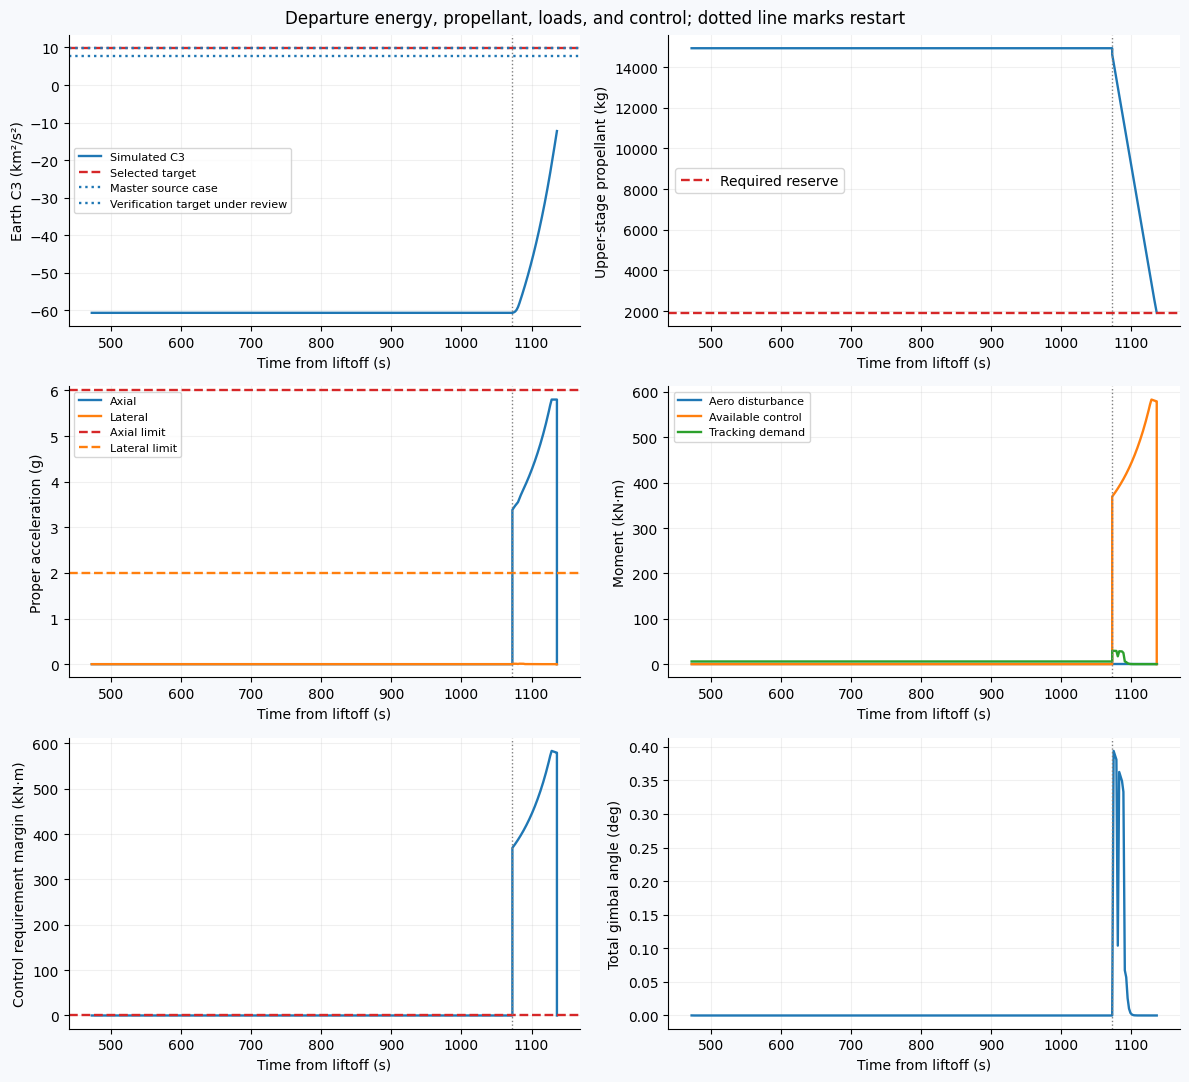

In [7]:
if departure is None:
    print("No departure plot: the ascent did not reach orbital cutoff.")
else:
    position = departure_history[["eci_x_m", "eci_y_m", "eci_z_m"]].to_numpy()
    velocity = departure_history[["eci_vx_m_s", "eci_vy_m_s", "eci_vz_m_s"]].to_numpy()
    c3 = (np.sum(velocity**2, axis=1) - 2 * MU / np.linalg.norm(position, axis=1)) / 1e6
    time = departure_history.t_s
    
    figure, axes = plt.subplots(3, 2, figsize=(12, 11))
    axes[0, 0].plot(time, c3, label="Simulated C3")
    axes[0, 0].axhline(departure_inputs["target_c3_km2_s2"], color="tab:red", ls="--", label="Selected target")
    for target in departure_targets["targets"]:
        axes[0, 0].axhline(target["target_c3_km2_s2"], ls=":", label=target["label"])
    axes[0, 0].set_ylabel("Earth C3 (km²/s²)")
    axes[0, 0].legend(fontsize=8)
    axes[0, 1].plot(time, departure_history.prop2_kg)
    axes[0, 1].axhline(departure["required_residual_kg"], color="tab:red", ls="--", label="Required reserve")
    axes[0, 1].set_ylabel("Upper-stage propellant (kg)")
    axes[0, 1].legend()
    
    axes[1, 0].plot(time, departure_history.axial_g, label="Axial")
    axes[1, 0].plot(time, departure_history.lateral_g, label="Lateral")
    axes[1, 0].axhline(config["limits"]["axial_g"], color="tab:red", ls="--", label="Axial limit")
    axes[1, 0].axhline(config["limits"]["lateral_g"], color="tab:orange", ls="--", label="Lateral limit")
    axes[1, 0].set_ylabel("Proper acceleration (g)")
    axes[1, 0].legend(fontsize=8)
    for column, label in [("aero_moment_Nm", "Aero disturbance"), ("available_moment_Nm", "Available control"), ("required_moment_Nm", "Tracking demand")]:
        axes[1, 1].plot(time, departure_history[column] / 1000, label=label)
    axes[1, 1].set_ylabel("Moment (kN·m)")
    axes[1, 1].legend(fontsize=8)
    
    axes[2, 0].plot(time, departure_history.ratio2_margin_Nm / 1000)
    axes[2, 0].axhline(0, color="tab:red", ls="--")
    axes[2, 0].set_ylabel("Control requirement margin (kN·m)")
    axes[2, 1].plot(time, departure_history.gimbal_total_deg)
    axes[2, 1].set_ylabel("Total gimbal angle (deg)")
    for axis in axes.flat:
        axis.set_xlabel("Time from liftoff (s)")
        for event in departure["events"]:
            if event["event"] == "TMI_restart":
                axis.axvline(event["t_s"], color="grey", ls=":", lw=1)
    figure.suptitle("Departure energy, propellant, loads, and control; dotted line marks restart")
    figure.tight_layout()
    figures["departure"] = figure
    display(figure)
    plt.close(figure)


### Correlated load cases and events

Each row is one flight instant. Keep its forces, moments, mass, and acceleration
together when transferring loads to a structural model.

In [8]:
load_columns = {
    "case": "Load case", "t_s": "Time (s)", "altitude_m": "Altitude (m)",
    "mach": "Mach", "alpha_deg": "AoA (deg)", "q_Pa": "Q (Pa)",
    "axial_g": "Axial (g)", "lateral_g": "Lateral (g)",
    "normal_force_N": "Normal force (N)", "aero_moment_Nm": "Aero moment (N·m)",
}
show_table(simulation.load_cases[list(load_columns)].rename(columns=load_columns).round(3))
show_table(pd.DataFrame(summary["events"]))
if departure is not None:
    show_table(pd.DataFrame(departure["events"]))

Load case,Time (s),Altitude (m),Mach,AoA (deg),Q (Pa),Axial (g),Lateral (g),Normal force (N),Aero moment (N·m)
Max-Q,63.400,7787.302,0.834,0.308,17886.384,1.348,0.004,4398.162,154552.784
Max-Qalpha,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max axial acceleration,217.763,78223.853,12.830,2.273,162.961,5.688,0.001,411.119,6382.989
Max lateral acceleration,220.963,80173.685,12.986,3.435,120.661,1.134,0.018,525.025,2512.076
Max aerodynamic moment,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max TVC demand,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max thrust,0.000,18.201,0.025,90.000,45.112,1.305,0.000,144.257,5054.527
Max aerodynamic normal force,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011,25361.577,892656.526
Max aerodynamic axial force,76.400,11291.113,1.051,0.119,16754.353,1.377,0.002,2050.982,70742.613


event,t_s,shed_mass_kg,cg_shift_m,upper_delta_v_m_s,lower_delta_v_m_s
liftoff,0.000000,NaN,NaN,NaN,NaN
MECO,217.762831,NaN,NaN,NaN,NaN
stage_separation,219.762831,40744.129012,8.324391,0.5,-0.987756
stage2_ignition,219.762831,NaN,NaN,NaN,NaN
fairing_jettison,271.358436,2155.278250,NaN,NaN,NaN
orbital_speed_cutoff,472.676346,NaN,NaN,NaN,NaN
end_coast,502.676346,NaN,NaN,NaN,NaN


event,t_s,startup_propellant_kg
ascent_cutoff,472.676346,NaN
TMI_restart,1072.676346,301.843504
residual_propellant_limit,1136.225949,NaN


### Optional numerical sensitivity

Enable `studies.solver_refinement` in [checks.toml](inputs/checks.toml) to compare
solver settings. The saved study defines every change; it does not replace the
baseline flight or establish physical accuracy.

In [9]:
extra_tables = {"overview": key_results, "review": review_results}
if refinement_settings["enabled"]:
    from copy import deepcopy
    from model.trajectory import run_trajectory

    refined_config = deepcopy(simulation.c)
    refined_config["solver"]["rtol"] *= refinement_settings["rtol_scale"]
    refined_config["solver"]["max_step_s"] *= refinement_settings["max_step_scale"]
    refined_config["solver"]["output_step_s"] = refinement_settings["output_step_s"]
    show_table(pd.DataFrame({
        "Setting": ["rtol", "max_step_s", "output_step_s"],
        "Baseline": [simulation.c["solver"][key] for key in ["rtol", "max_step_s", "output_step_s"]],
        "Refined": [refined_config["solver"][key] for key in ["rtol", "max_step_s", "output_step_s"]],
    }))
    refined_flight, _, _ = run_trajectory(refined_config)
    quantities = ["q_Pa", "qalpha_Pa_deg", "axial_g", "lateral_g"]
    comparison = pd.DataFrame({
        "Quantity": quantities,
        "Baseline peak": flight[quantities].abs().max().to_numpy(),
        "Refined peak": refined_flight[quantities].abs().max().to_numpy(),
    })
    extra_tables["solver_sensitivity"] = comparison
    show_table(comparison)
else:
    print("Numerical sensitivity is disabled in the saved study settings.")

Numerical sensitivity is disabled in the saved study settings.


## 5. What the results mean

The model includes changing mass/CG/inertia, a layered atmosphere and wind,
Mach/AoA interpolation, actuator and acceleration limits, and stage/fairing
separation. It does not calculate flexibility, vibration, shock, or separation
clearance. Out-of-table aerodynamic samples and assumed control capabilities
limit the conclusions even when a numerical check passes.

Read [summary.md](outputs/current/summary.md) for saved findings,
[plots](outputs/current/plots/) for figures, [tables](outputs/current/tables/)
for numerical results, and [inputs_used](outputs/current/inputs_used/) for the
exact settings. Continue to [Engineering checks](02_Engineering_Checks.ipynb).

In [10]:
output_folder = save_flight(
    context, departure=departure, figures=figures,
    tables=extra_tables, expected_inputs=run_inputs,
)
print("Saved simulation results to:", output_folder)

Saved simulation results to: C:\Users\maxwe\.codex\.chatgpt-projects\g-p-6a9464860c90819188ae3dd3be539576\Hyperion\outputs\current
